# MARIO Task 1 Training Dashboard

This notebook runs the MARIO model pipeline for the Task 1 exploratory setup that uses the images currently available in `Task_1/test`. It helps you:
- create patient-grouped folds
- fetch the pretrained DINO encoder
- cache classic-preprocessed images
- extract image features
- train the Task 1 head/forecaster
- visualize validation metrics and saved predictions

> Important: the data used here is exploratory. Only the labeled CSV rows whose referenced B-scans are present locally are used, so these are not official challenge results.

This exploratory notebook retains DINO-only executable cells. Its saved outputs are historical; see the separate alternative-encoder CLI examples at the end.


In [4]:
import json
import os
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml
from sklearn.metrics import confusion_matrix

# Use the repository root as the working directory when the notebook is launched from the repo root.
REPO = Path.cwd()
if not (REPO / 'mario_dino').exists():
    REPO = REPO.parent

print(f'Repo root: {REPO}')

venv_python = REPO / '.venv' / ('Scripts' if os.name == 'nt' else 'bin') / ('python.exe' if os.name == 'nt' else 'python')
PYTHON = str(venv_python) if venv_python.exists() else sys.executable
print(f'Python executable: {PYTHON}')

cfg_path = REPO / 'outputs' / 'task1_present_cv_exploratory' / 'config.yaml'
print(f'Config: {cfg_path}')
assert cfg_path.exists(), 'Config not found. Run the setup once before opening this notebook.'


Repo root: c:\Users\Yug Patel\OneDrive\Desktop\yug_mario\mario
Python executable: c:\Users\Yug Patel\OneDrive\Desktop\yug_mario\mario\.venv\Scripts\python.exe
Config: c:\Users\Yug Patel\OneDrive\Desktop\yug_mario\mario\outputs\task1_present_cv_exploratory\config.yaml


In [5]:
def run_python(args, cwd=REPO, check=True):
    cmd = [PYTHON, *args]
    print(f"Running: {' '.join(cmd)}")
    proc = subprocess.run(cmd, cwd=str(cwd), capture_output=True, text=True)
    if proc.stdout:
        print(proc.stdout)
    if proc.returncode != 0 and check:
        print(proc.stderr)
        raise RuntimeError(f"Command failed ({proc.returncode}): {' '.join(cmd)}")
    return proc

def load_cfg(path):
    with open(path, 'r', encoding='utf-8') as f:
        return yaml.safe_load(f)

cfg = load_cfg(cfg_path)
print(json.dumps({k: cfg[k] for k in ['preprocess', 'encoder', 'features', 'train'] if k in cfg}, indent=2, default=str))


{
  "preprocess": {
    "mode": "classic",
    "cache_dir": "C:\\Users\\Yug Patel\\OneDrive\\Desktop\\yug_mario\\mario\\outputs\\task1_present_cv_exploratory\\cache"
  },
  "encoder": {
    "weights": "C:\\Users\\Yug Patel\\OneDrive\\Desktop\\yug_mario\\mario\\outputs\\task1_present_cv_exploratory\\weights\\vit_base_patch14_reg4_dinov2.lvd142m.pth"
  },
  "features": {
    "store_dir": "C:\\Users\\Yug Patel\\OneDrive\\Desktop\\yug_mario\\mario\\outputs\\task1_present_cv_exploratory\\features",
    "dtype": "float16",
    "batch_size": 1,
    "chunk_size": 128,
    "num_workers": 0,
    "amp": true
  },
  "train": {
    "out_dir": "C:\\Users\\Yug Patel\\OneDrive\\Desktop\\yug_mario\\mario\\outputs\\task1_present_cv_exploratory\\heads",
    "max_epochs": 50,
    "patience": 8
  }
}


In [6]:
# 1) Build patient-grouped folds
run_python(['-m', 'mario_dino.data.splits', '--config', str(cfg_path)])

# 2) Download pretrained DINOv2 weights for the selected encoder
run_python(['scripts/fetch_weights.py', '--config', str(cfg_path)])

print('Fold generation and weight fetch complete.')


Running: c:\Users\Yug Patel\OneDrive\Desktop\yug_mario\mario\.venv\Scripts\python.exe -m mario_dino.data.splits --config c:\Users\Yug Patel\OneDrive\Desktop\yug_mario\mario\outputs\task1_present_cv_exploratory\config.yaml
wrote 19 patient assignments across 4 folds to C:\Users\Yug Patel\OneDrive\Desktop\yug_mario\mario\outputs\task1_present_cv_exploratory\splits.json

Running: c:\Users\Yug Patel\OneDrive\Desktop\yug_mario\mario\.venv\Scripts\python.exe scripts/fetch_weights.py --config c:\Users\Yug Patel\OneDrive\Desktop\yug_mario\mario\outputs\task1_present_cv_exploratory\config.yaml
C:\Users\Yug Patel\OneDrive\Desktop\yug_mario\mario\outputs\task1_present_cv_exploratory\weights\vit_base_patch14_reg4_dinov2.lvd142m.pth exists; pass --force to overwrite

Fold generation and weight fetch complete.


In [7]:
# 3) Preprocess images and extract features
run_python(['-m', 'mario_dino.octip_cache', '--config', str(cfg_path), '--mode', 'classic'])
run_python(['-m', 'mario_dino.features', '--config', str(cfg_path), '--device', 'auto'])

print('Classic cache and feature extraction complete.')


Running: c:\Users\Yug Patel\OneDrive\Desktop\yug_mario\mario\.venv\Scripts\python.exe -m mario_dino.octip_cache --config c:\Users\Yug Patel\OneDrive\Desktop\yug_mario\mario\outputs\task1_present_cv_exploratory\config.yaml --mode classic
Running: c:\Users\Yug Patel\OneDrive\Desktop\yug_mario\mario\.venv\Scripts\python.exe -m mario_dino.features --config c:\Users\Yug Patel\OneDrive\Desktop\yug_mario\mario\outputs\task1_present_cv_exploratory\config.yaml --device auto
Classic cache and feature extraction complete.


In [8]:
# 4) Train the Task 1 heads and forecaster
run_python(['-m', 'mario_dino.train_heads', '--config', str(cfg_path), '--device', 'auto'])

print('Training complete. Result files are stored under the output directory.')


Running: c:\Users\Yug Patel\OneDrive\Desktop\yug_mario\mario\.venv\Scripts\python.exe -m mario_dino.train_heads --config c:\Users\Yug Patel\OneDrive\Desktop\yug_mario\mario\outputs\task1_present_cv_exploratory\config.yaml --device auto
Training complete. Result files are stored under the output directory.


In [9]:
# Inspect final metrics and output tables
output_dir = REPO / 'outputs' / 'task1_present_cv_exploratory'
heads_dir = output_dir / 'heads'
metrics_path = heads_dir / 'metrics.json'
oof_path = heads_dir / 'oof_task1.csv'

metrics = json.loads(metrics_path.read_text(encoding='utf-8'))
print(json.dumps(metrics['task1']['oof'], indent=2, sort_keys=True))

oof = pd.read_csv(oof_path)
print(f'OOF rows: {len(oof)}')
print(oof.head())


{
  "F1_score": 0.5442386831275721,
  "Rk-correlation": 0.18275423419486456,
  "Specificity": 0.8102468774183477
}
OOF rows: 1944
    case  id_patient  fold  y_true  y_pred   logit_0   logit_1   logit_2  \
0  13024          56     0       1       1  0.692990  3.138069  0.636059   
1  13025          56     0       1       1  0.295456  3.371169  0.156046   
2  13026          56     0       1       1 -0.674236  2.877866  0.030573   
3  13027          56     0       1       1  0.019997  3.916596 -0.330427   
4  13028          56     0       1       1  1.273110  2.257318  0.461167   

    logit_3  
0 -0.498912  
1  0.060576  
2  0.716185  
3  1.283134  
4  0.283616  


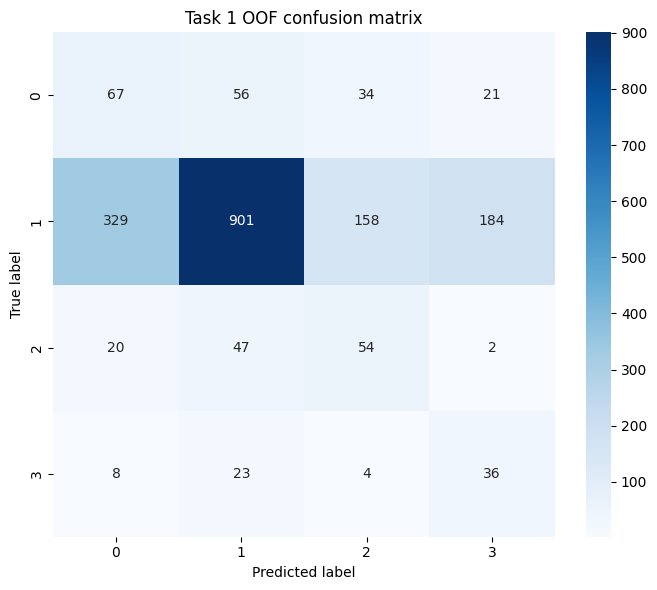

In [10]:
# Plot a confusion matrix from the out-of-fold predictions
oof = pd.read_csv(heads_dir / 'oof_task1.csv')
y_true = oof['y_true'].astype(int).to_numpy()
y_pred = oof['y_pred'].astype(int).to_numpy()
labels = np.arange(4)
cm = confusion_matrix(y_true, y_pred, labels=labels)

plot_dir = output_dir / 'plots'
plot_dir.mkdir(exist_ok=True, parents=True)

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['0','1','2','3'], yticklabels=['0','1','2','3'], ax=ax)
ax.set_xlabel('Predicted label')
ax.set_ylabel('True label')
ax.set_title('Task 1 OOF confusion matrix')
fig.tight_layout()
fig.savefig(plot_dir / 'task1_confusion_matrix.png', dpi=200)
plt.show()


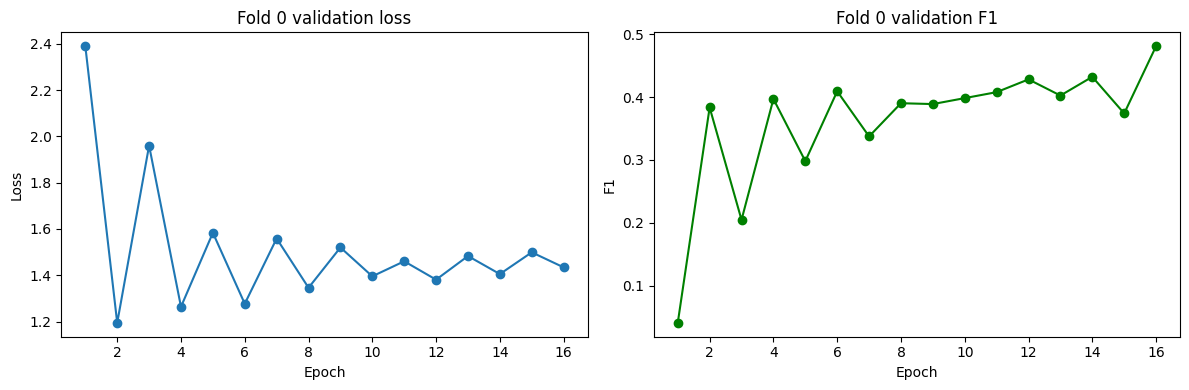

In [11]:
# Plot per-fold validation history for the first fold
fold0_hist = json.loads((heads_dir / 'fold0' / 'history.json').read_text(encoding='utf-8'))
hist = fold0_hist['stage_a']
epoch = [h['epoch'] for h in hist]
val_loss = [h['val_loss'] for h in hist]
val_f1 = [h['val_F1_score'] for h in hist]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epoch, val_loss, marker='o')
axes[0].set_title('Fold 0 validation loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')

axes[1].plot(epoch, val_f1, marker='o', color='green')
axes[1].set_title('Fold 0 validation F1')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('F1')
fig.tight_layout()
fig.savefig(plot_dir / 'task1_fold0_history.png', dpi=200)
plt.show()


## Quick next steps

1. Adjust the config in `outputs/task1_present_cv_exploratory/config.yaml` if you want to change the preprocessing mode, batch size, or output directory.
2. Re-run the notebook cells as needed after changing data or model settings.
3. Open the saved images in the output folder: `outputs/task1_present_cv_exploratory/plots` and the model checkpoints under `.../heads/fold*/`.
4. For a single run, use the `run_python(...)` helper to execute any repo CLI command without leaving Jupyter.


## Alternative encoder training on the cloud instance

The executable cells above retain the DINO frozen-feature workflow. Their previews use the legacy
DINO transform, weight preparation assumes timm DINO weights, and training reads the feature store.
Changing only the config path does not turn this dashboard into full encoder fine-tuning or provide
live tracking for `train_finetune`. Use these separate CLI commands from the repository root instead:

```bash
python scripts/fetch_weights.py --config configs/task1_convnext.yaml
python -m mario_dino.data.splits --config configs/task1_convnext.yaml
python -m mario_dino.train_finetune --config configs/task1_convnext.yaml --device cuda
python -m mario_dino.infer --config configs/task1_convnext.yaml --task 1 --csv /path/to/task1.csv --device cuda
```

For VisionFM OCT, manually prepare `weights/VFM_OCT_weights.pth`, then use
`configs/task1_visionfm.yaml`. That preset assumes raw backbone weights; select
`--set encoder.checkpoint_key=teacher` (or `student` / `visionfm_state_dict`) only for a file
with that wrapper. The released OCT layout remains unverified. Wrapped Namespace metadata needs
PyTorch >=2.4. The new presets use their own input transforms and `[192, 512]` inputs.

`train_finetune` reads cached image pairs, trains Task 1 encoder/heads together and writes history,
OOF predictions and self-contained `fold{k}/task1.pt` files to `outputs/convnext_finetune` or
`outputs/visionfm_finetune`. It does not use pooled features or prefix tokens. Inference loads
one fold encoder at a time using its saved transform and needs no original source weight file.
`train_partial` remains DINO-only. DINO-trained heads are not interchangeable with these encoders.
For a frozen alternative baseline, follow the runbook and override inference `--run-dir` to its
`outputs/convnext_heads` or `outputs/visionfm_heads` directory.

See [the encoder reference](../docs/encoders.md) and
[cloud instructions](../RUNBOOK.md#alternative-task-1-encoders-convnext-and-visionfm-oct).
These are commands for later execution. No notebook cells, CPU/GPU models, training, inference,
pretrained binaries or new runtime tests were run to document this extension. Saved outputs
in this notebook predate it and do not validate the alternative encoders.
